# Multiple lineare Regression



Bisher haben wir uns nur Probleme der einfachen linearen Regression angesehen. Lineare Regression lässt sich aber auch mit mehr als einer erklärenden Variable einsetzen, um die Zielvariable (Target) zu beschreiben.



## Lernziele


Am Ende dieses Notebooks solltest du:
- multiple lineare Regression mit scikit-learn anwenden können.
- Modelle der multiplen linearen Regression interpretieren können.
- erklären können, warum es besser ist, das **adjustierte $R^2$** (adjusted $R^2$) statt $R^2$ zu verwenden, um Modelle der multiplen linearen Regression zu vergleichen.

## Wiederholung



### Das multiple Regressionsmodell

 

Die multiple lineare Regression ist der einfachen linearen Regression sehr ähnlich. Der Unterschied: Die abhängige Variable $y$ wird durch $k$ unabhängige Variablen $x_1, \dots, x_k$ beschrieben.

$$
y = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_k x_k + e
$$ 

Die Formel für unser **vorhergesagtes Modell** lautet

$$\hat{y} = b_0  + b_1  x_1 + b_2  x_2 + \dots + b_k  x_k$$

wobei $b_0$ der geschätzte Achsenabschnitt (intercept) ist und $b_1, b_2,$... die Koeffizienten (coefficients) unserer Features sind.
* **Achsenabschnitt**: Die Interpretation bleibt dieselbe wie bei der einfachen linearen Regression. Er ist der Wert von $y$, wenn alle $x$ gleich 0 sind.
* **Koeffizienten**: Bei der Interpretation der Koeffizienten müssen wir genauer sein: $b_i$ ist die Veränderung von $y$, wenn sich $x_i$ um eine Einheit ändert und **alle anderen Variablen konstant gehalten werden**  

## Starten wir mit einem Beispiel



Für dieses Beispiel verwenden wir wieder einen Datensatz über Autos. Diesmal ist er etwas umfangreicher, mit mehr Beobachtungen und Features. Unser Ziel bleibt aber, `mpg` anhand verschiedener Fahrzeugmerkmale vorherzusagen.

In [1]:
# Pakete importieren
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Stil und Größe der Abbildungen für das gesamte Notebook festlegen
sns.set_style("ticks")
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
# Datensatz importieren
cars = pd.read_csv("data/cars_multivariate.csv")
cars.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## Einfache lineare Regression



Wie zuvor verwenden wir zuerst ein einfaches lineares Regressionsmodell mit dem Feature `horsepower` und schauen, wie gut es zu unseren Daten passt. 

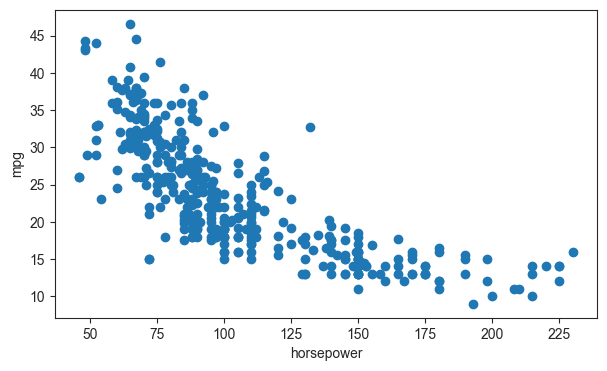

In [3]:
# Zusammenhang zwischen horsepower und mpg plotten
plt.scatter(cars.horsepower, cars.mpg)
plt.ylabel("mpg")
plt.xlabel("horsepower");

In [4]:
# Feature und Zielvariable definieren
X = cars[["horsepower"]]
y = cars["mpg"]

X.shape

(392, 1)

In [5]:
# Lineares Regressionsmodell anpassen (fitten)
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# R-Quadrat (r-squared) berechnen
y_hat = lin_reg.predict(X)
print("R-squared:", round(r2_score(y, y_hat), 3))

R-squared: 0.606


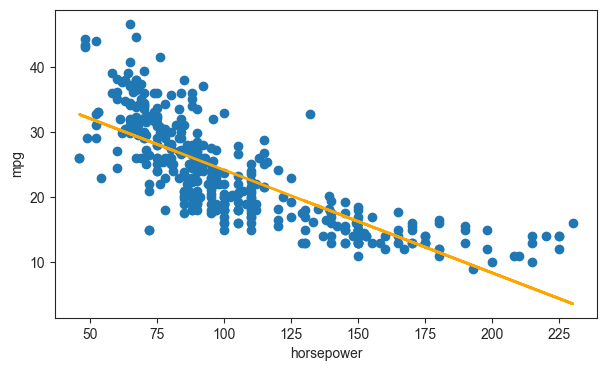

In [6]:
# Daten mit Regressionsgerade plotten
plt.scatter(X, y)
plt.plot(X, y_hat, "-", color="orange", linewidth=2)
plt.ylabel("mpg")
plt.xlabel("horsepower");

Laut $R^2$ (Bestimmtheitsmaß) kann das Feature `horsepower` 60,6 % der Varianz unserer Zielvariable erklären. 

## Multiple lineare Regression  



Statt `horsepower` als einzige unabhängige Variable zur Vorhersage von `mpg` zu nutzen, können wir weitere unabhängige Variablen ins Modell aufnehmen, um die Anpassung zu verbessern. Versuchen wir, `weight` zum Modell hinzuzufügen.

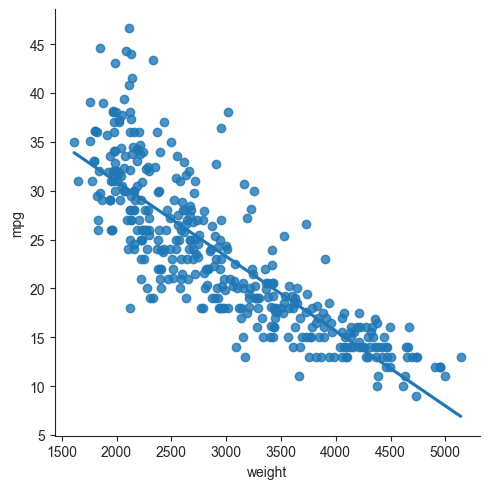

In [7]:
# Zusammenhang zwischen weight und mpg plotten
# Mit der seaborn-Funktion .lmplot können wir unsere Daten inklusive Regressionsgerade plotten
sns.lmplot(x="weight", y="mpg", data=cars, ci=None);

In [8]:
# Modell-Input X mit zwei Features definieren
X2 = cars[["horsepower", "weight"]]
y2 = cars.mpg

X2.shape

(392, 2)

In [9]:
# Lineares Regressionsmodell anpassen (fitten)
lin_reg2 = LinearRegression()
lin_reg2.fit(X2, y2)

# Achsenabschnitt und Koeffizienten berechnen
intercept = lin_reg2.intercept_
coefficients = lin_reg2.coef_
print("Intercept:", intercept.round(4))
print("Coefficients:", coefficients.round(4))

Intercept: 45.6402
Coefficients: [-0.0473 -0.0058]


In [10]:
# R-Quadrat (r-squared) berechnen
y_hat2 = lin_reg2.predict(X2)
print("R-squared:", round(r2_score(y2, y_hat2), 3))

R-squared: 0.706


### Interpretation des Modells



Beschreibt dieses Modell die Varianz von `mpg` besser als die einfache lineare Regression? Es sieht so aus. Dieses Modell erklärt etwa 70 % der Variation von `mpg`.

Unser multiples Regressionsmodell lautet

$$ \hat{mpg} = 45.6402 - 0.0473 \times horsepower - 0.0058 \times weight $$

Interpretieren wir, was wir hier sehen...
* Der erwartete `mpg`-Wert für ein Auto mit `horsepower` und `weight` von 0 ist 45,6402 (theoretisch...).
* Wir erwarten, dass `mpg` um 0,0473 sinkt, wenn `horsepower` um 1 steigt, **wobei `weight` konstant gehalten wird**.
* Wir erwarten, dass `mpg` um 0,0058 sinkt, wenn `weight` um 1 steigt, **wobei `horsepower` konstant gehalten wird**.

### Vorhersagen für neue Autos



Welcher `mpg`-Wert wird für ein Auto mit 200 `horsepower` und einem `weight` von 3500 vorhergesagt?

$$
\hat{mpg} = 45.6402 - 0.0473 (200) - 0.0058 (3500) = 15.88
$$


Wir würden für dieses Auto einen `mpg`-Wert von 15,88 erwarten.
Das lässt sich natürlich auch mit unserem Modell berechnen. Wir müssen nur die Funktion `.predict()` aufrufen und ihr die Werte von X übergeben.

In [11]:
# Vorhersage für ein neues Auto mit horsepower=200 und weight=3500
new_car = pd.DataFrame({"horsepower": [200], "weight": [3500]})
y_prediction = lin_reg2.predict(new_car)
print("Prediction for new car:", y_prediction[0].round(3))

Prediction for new car: 15.9


### Multiple Regression erkunden



Leider lässt sich multiple lineare Regression nicht so leicht darstellen. Verwenden wir aber nur zwei unabhängige Variablen zur Vorhersage einer abhängigen Variable, können wir das noch mit einem 3D-Plot grafisch zeigen.

Jetzt versuchen wir, die Datenpunkte und unser angepasstes lineares Modell auf den drei Achsen (`horsepower`, `weight` und `mpg`) zu plotten. Mit zwei statt einer unabhängigen Variable wird unser Modell nicht durch eine Linie dargestellt, sondern durch eine 2D-Ebene.

In der Zelle unten findest du den Code für diesen 3D-Plot. Vorher musst du allerdings ein paar Variablen definieren.

Der Befehl
```Python:
%matplotlib widget
```
aktiviert interaktive 3D-Plots, sodass du deine Ansicht auf die Daten verändern kannst. (Wenn der Plot nach dem Ausführen der Zelle nicht angezeigt wird, führ die Zelle einfach noch einmal aus... das sollte das Problem lösen :) )

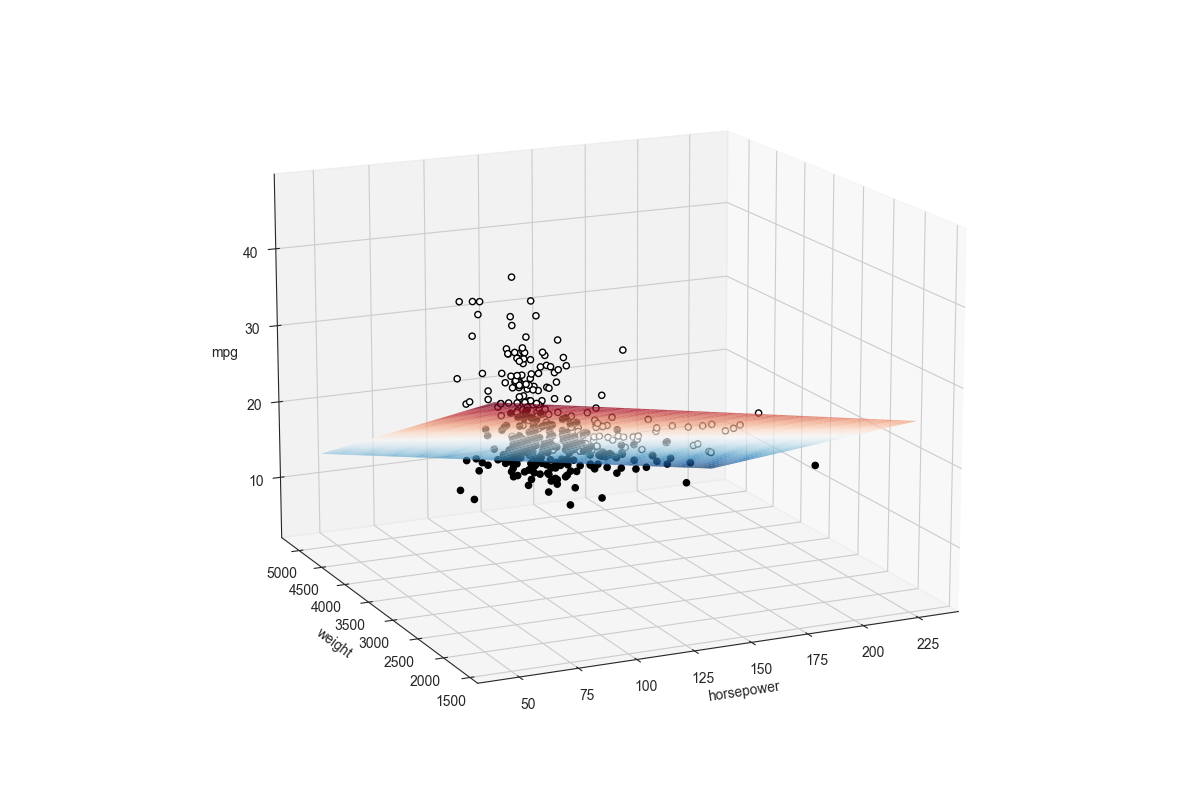

In [12]:
# Diesen Plot haben wir übernommen und angepasst von https://www.datarobot.com/blog/multiple-regression-using-statsmodels/#appendix

from mpl_toolkits.mplot3d import Axes3D

# Interaktiven Plot aktivieren
%matplotlib widget

# Du musst einige Variablen für den Achsenabschnitt und die Koeffizienten deines Modells definieren
intercept = lin_reg2.intercept_
coef_horsepower = lin_reg2.coef_[0]
coef_weight = lin_reg2.coef_[1]

# horsepower/weight-Gitter für den 3D-Plot erstellen
xx1, xx2 = np.meshgrid(
    np.linspace(X2.horsepower.min(), X2.horsepower.max(), 100),
    np.linspace(X2.weight.min(), X2.weight.max(), 100),
)

# Hyperebene (HP, hyperplane) plotten, indem die Parameter auf dem Gitter ausgewertet werden
# Die folgende Zeile ist unsere Regressionsgleichung
Z = intercept + coef_horsepower * xx1 + coef_weight * xx2


# 3D-Abbildung in matplotlib erstellen
fig = plt.figure(figsize=(12, 8))
ax = Axes3D(fig, azim=-115, elev=15, auto_add_to_figure=False)
fig.add_axes(ax)

# Hyperebene plotten
surf = ax.plot_surface(xx1, xx2, Z, cmap=plt.cm.RdBu_r, alpha=0.8, linewidth=0)

# Residuen (residuals) berechnen
resid = y2 - y_hat2

# Datenpunkte plotten: Punkte über der HP sind weiß, Punkte darunter schwarz
ax.scatter(
    X2[resid >= 0].horsepower,
    X2[resid >= 0].weight,
    y2[resid >= 0],
    color="black",
    alpha=1.0,
    facecolor="white",
)
ax.scatter(
    X2[resid < 0].horsepower,
    X2[resid < 0].weight,
    y2[resid < 0],
    color="black",
    alpha=1.0,
)

# Achsenbeschriftungen setzen
ax.set_xlabel("horsepower")
ax.set_ylabel("weight")
ax.set_zlabel("mpg")
plt.show();

> [!NOTE]
> Wenn die Zelle oben einen Fehler ausgibt oder der 3D-Plot nicht funktioniert, führ die Python-Datei `plot_3d_regression.py` im Terminal aus.

```bash
uv run python plot_3d_regression.py
```

#### Erklärung
%matplotlib widget gilt in VS-Code-Notebooks als unzuverlässig, selbst wenn ipympl installiert ist. Der Notebook-Renderer von VS Code unterstützt das Widget-Backend nicht vollständig.

Um die Interaktivität für die folgenden Plots abzuschalten, müssen wir `%matplotlib inline` erneut ausführen.

In [13]:
%matplotlib inline

## Weitere Variablen hinzufügen



Versuchen wir jetzt, `mpg` mit `displacement`, `horsepower`, `weight` und `acceleration` vorherzusagen. 

In [14]:
# Korrelation der Variablen ausgeben
cars[["displacement", "horsepower", "weight", "acceleration"]].corr()

,displacement,horsepower,weight,acceleration
displacement,1.000000,0.897257,0.932994,-0.543800
horsepower,0.897257,1.000000,0.864538,-0.689196
weight,0.932994,0.864538,1.000000,-0.416839
acceleration,-0.543800,-0.689196,-0.416839,1.000000


Du siehst, dass es zwischen diesen Variablen einige Korrelationen gibt! Diese Korrelationen sind auch in den Streudiagrammen (scatter plots) zu erkennen:

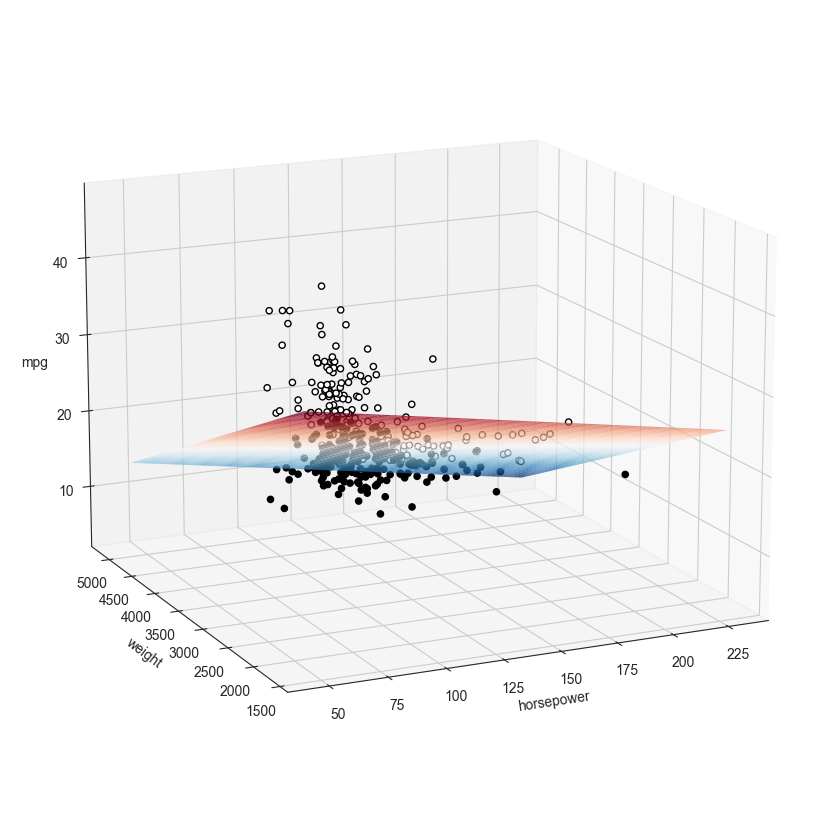

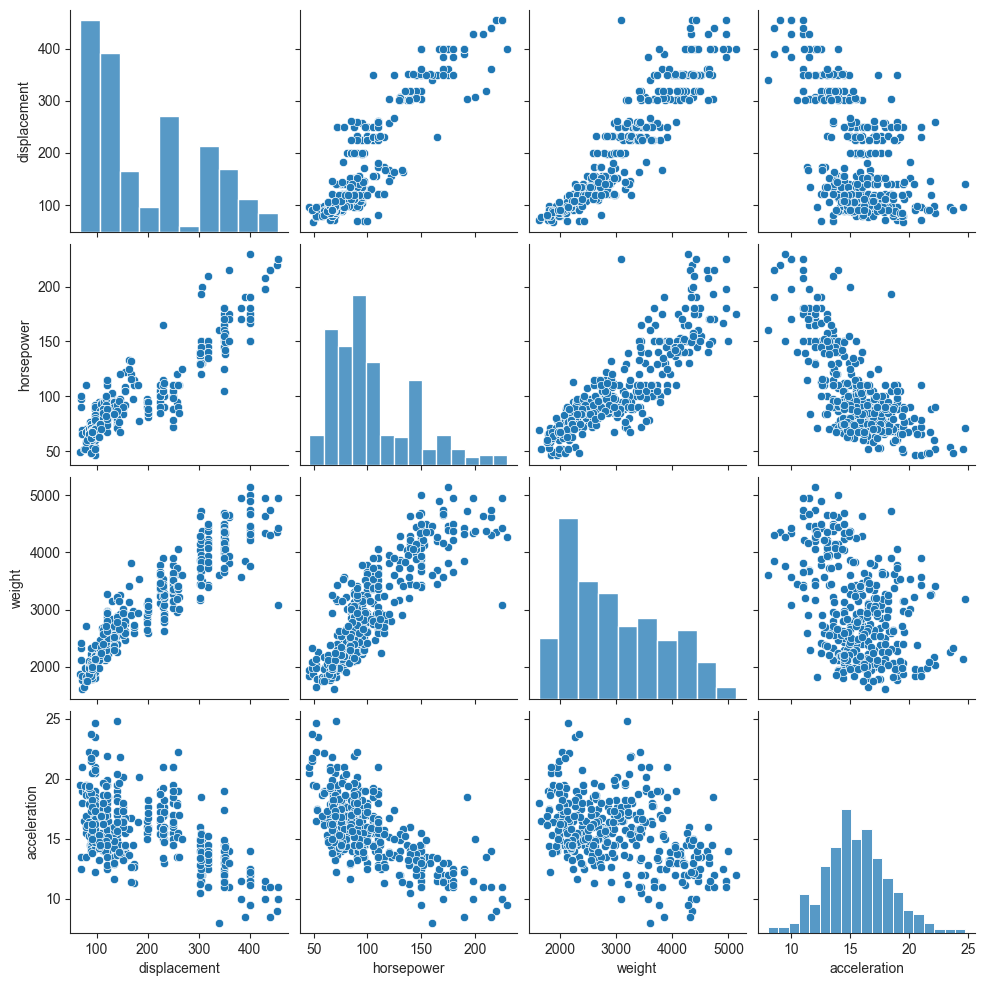

In [15]:
# Pair Plot der möglichen Features plotten
sns.pairplot(cars[["displacement", "horsepower", "weight", "acceleration"]]);

In [16]:
# Modell mit mehreren Variablen definieren und anpassen
X3 = cars[["horsepower", "weight", "displacement", "acceleration"]]
y3 = cars.mpg

# Lineares Regressionsmodell anpassen (fitten)
lin_reg3 = LinearRegression()
lin_reg3.fit(X3, y3)

# Achsenabschnitt und Koeffizienten berechnen
intercept = lin_reg3.intercept_
coefficients = lin_reg3.coef_
print("Intercept:", intercept.round(4))
print("Coefficients:", coefficients.round(4))

Intercept: 45.2511
Coefficients: [-0.0436 -0.0053 -0.006  -0.0231]


In [17]:
# R-Quadrat (r-squared) berechnen
y_hat3 = lin_reg3.predict(X3)
print("R-squared:", round(r2_score(y3, y_hat3), 3))

R-squared: 0.707


Hinterfrage dein Modell immer! Hier sind ein paar Fragen, die du jetzt beantworten können solltest:

1. Wie gut ist die Modellanpassung (model fit)?

**Antwort:** $R^2$ = 0,707. Die vier Features erklären etwa 70,7 % der Varianz von `mpg`. Das ist eine recht gute Anpassung. Rund 29 % der Varianz bleiben unerklärt.

Im Vergleich: Das Modell mit nur `horsepower` und `weight` kam schon auf 0,706. Die zwei zusätzlichen Features bringen also fast nichts.

<br>

<details><summary>
Zeig mir die Antwort
</summary>

Das Modell hat ein R-Quadrat (R-squared) von etwa 0,707 (bzw. 70,7 %). Das bedeutet, dass etwa 70,7 % der Varianz von `mpg` durch die vier Features erklärt werden: `horsepower`, `weight`, `displacement` und `acceleration`. Das ist eine recht gute Anpassung, allerdings bleiben noch etwa 29 % der Varianz durch das Modell unerklärt.

</details>

2. Wie lautet die Regressionsgleichung?

**Antwort:**

$$
\hat{mpg} = 45.2511 - 0.0436 \times horsepower - 0.0053 \times weight - 0.0060 \times displacement - 0.0231 \times acceleration
$$

<details><summary>
Zeig mir die Antwort
</summary>

$$
\hat{mpg} = 45.2511 - 0.0436 \times horsepower - 0.0053 \times weight - 0.0060 \times displacement - 0.0231 \times acceleration
$$

</details>


3. Wie können wir das Modell interpretieren?

**Antwort:**
- **Achsenabschnitt (45,25):** erwarteter `mpg`-Wert, wenn alle vier Features 0 sind. Nur theoretisch, kein Auto hat 0 PS und 0 Gewicht.
- **horsepower (-0,0436):** 1 PS mehr, `mpg` sinkt um 0,0436, wenn die anderen drei Features gleich bleiben.
- **weight (-0,0053):** 1 Pfund mehr, `mpg` sinkt um 0,0053, die anderen Features konstant.
- **displacement (-0,0060):** 1 Kubikzoll mehr Hubraum, `mpg` sinkt um 0,0060, die anderen Features konstant.
- **acceleration (-0,0231):** 1 Sekunde mehr Beschleunigungszeit, `mpg` sinkt um 0,0231, die anderen Features konstant.

Vorsicht: Die Features sind stark miteinander korreliert (siehe Korrelationstabelle). Die einzelnen Koeffizienten sind deshalb unsicher, "die anderen konstant halten" kommt in den echten Daten kaum vor.

<details><summary>
Hier klicken für die Lösung
</summary>

+  **Achsenabschnitt (45.2511**): Der erwartete `mpg`-Wert für ein Auto, bei dem alle Features (`horsepower`, `weight`, `displacement`, `acceleration`) gleich 0 sind, läge bei 45,2511 (das ist allerdings theoretisch und praktisch nicht sinnvoll).
+  **Koeffizient von Horsepower (-0.0436)**: Für jede Erhöhung von `horsepower` um 1 Einheit erwarten wir, dass `mpg` um 0,0436 sinkt, wobei `weight`, `displacement` und `acceleration` konstant gehalten werden.
+  **Koeffizient von Weight (-0.0053)**: Für jede Erhöhung von `weight` um 1 Einheit erwarten wir, dass `mpg` um 0,0053 sinkt, wobei `horsepower`, `displacement` und `acceleration` konstant gehalten werden.
+  **Koeffizient von Displacement (-0.0060)**: Für jede Erhöhung von `displacement` um 1 Einheit erwarten wir, dass `mpg` um 0,0060 sinkt, wobei `horsepower`, `weight` und `acceleration` konstant gehalten werden.
+  **Koeffizient von Acceleration (-0.0231)**: Für jede Erhöhung von `acceleration` um 1 Einheit erwarten wir, dass `mpg` um 0,0231 sinkt, wobei `horsepower`, `weight` und `displacement` konstant gehalten werden.

Alle Koeffizienten sind negativ. Das heißt: Steigt eines dieser Fahrzeugmerkmale, geht das mit geringerer Kraftstoffeffizienz (niedrigerem `mpg`) einher, wenn die anderen Variablen konstant gehalten werden.

</details>

## $R^2$ vs. adjustiertes $R^2$



Bei der multiplen linearen Regression sollte $R^2$ nicht die Metrik deiner Wahl sein, um die Modellanpassung zu bewerten. Wenn wir unserem Modell neue Features hinzufügen, bleibt $R^2$ entweder gleich oder steigt, selbst wenn diese zusätzlichen Features gar keinen Zusammenhang mit unserer Zielvariable haben. Das verleitet stark dazu, immer mehr Features ins Modell aufzunehmen. Das ist aber keine gute Idee! Normalerweise wollen wir ein gutes Modell trainieren, **aber** auf die einfachstmögliche Weise.

Hier kommt das **adjustierte $R^2$** (adjusted $R^2$) ins Spiel. Das adjustierte $R^2$ bestraft uns dafür, Features hinzuzufügen, die unser bestehendes Modell eigentlich nicht verbessern. Bei einer einfachen linearen Regression sind $R^2$ und adjustiertes $R^2$ nahezu gleich. Je mehr nicht signifikante Features wir einem Modell hinzufügen, desto größer wird der Abstand zwischen diesen beiden Metriken. Außerdem ist das adjustierte $R^2$ eine nützliche Metrik, wenn wir mehrere Modelle mit unterschiedlich vielen Features vergleichen wollen.

Die Formel des adjustierten $R^2$ lautet:
$$
R_a^2 = 1 - \frac{(1 - R^2) (n - 1)}{n - p - 1}
$$

wobei $n$ die Anzahl der Beobachtungen im Datensatz und $p$ die Anzahl der Features ist.

Leider bietet scikit-learn keine eingebaute Funktion zur Berechnung des adjustierten $R^2$. Wir können aber mit der Formel von oben unsere eigene Funktion schreiben:

In [18]:
# Funktion zur Berechnung des adjustierten R-Quadrats definieren
def adjusted_r_squared(r_squared, X):
    adjusted_r2 = 1 - ((1 - r_squared) * (len(X) - 1) / (len(X) - X.shape[1] - 1))
    return adjusted_r2

### Übung



Berechne das adjustierte $R^2$ für die drei Modelle, die du in diesem Notebook trainiert hast. Welches ist laut dieser Metrik das beste Modell?

In [ ]:
# R² und adjustiertes R² für alle drei Modelle
modelle = {
    "1: horsepower": (y, y_hat, X),
    "2: horsepower, weight": (y2, y_hat2, X2),
    "3: horsepower, weight, displacement, acceleration": (y3, y_hat3, X3),
}

vergleich = pd.DataFrame(
    {
        name: {
            "R2": r2_score(ziel, vorhersage),
            "adj. R2": adjusted_r_squared(r2_score(ziel, vorhersage), features),
        }
        for name, (ziel, vorhersage, features) in modelle.items()
    }
).T.round(4)

vergleich

**Antwort:**

| Modell | $R^2$ | adj. $R^2$ |
|---|---|---|
| 1: horsepower | 0,6059 | 0,6049 |
| 2: horsepower, weight | 0,7064 | **0,7049** |
| 3: alle vier Features | 0,7070 | 0,7040 |

- Bestes Modell nach adjustiertem $R^2$: **Modell 2** (`horsepower` und `weight`).
- Modell 3 hat zwar das höchste $R^2$, aber `displacement` und `acceleration` bringen kaum Erklärungskraft. Das adjustierte $R^2$ bestraft die zwei zusätzlichen Features, deshalb fällt es unter Modell 2.

<br>

<details><summary>
Zeig mir die Antwort
</summary>

Das beste Modell ist das mit dem höchsten adjustierten $R^2$. Das ist das Modell mit zwei Features: `horsepower` und `weight`.

</details>

## Zusammenfassung



- Wir erweitern das lineare Regressionsmodell, sodass es viele erklärende Variablen/Features enthält.
- Alle erklärenden Variablen sollten voneinander unabhängig sein.
- Mit $R^2$ können wir messen, wie gut ein Modell zu den Daten passt.
- Das adjustierte $R^2$ bestraft das Hinzufügen nicht nützlicher erklärender Variablen. Es eignet sich, um Modelle mit unterschiedlich vielen unabhängigen Variablen zu vergleichen.